<div style="text-align: justify; max-width: 90ch">

# Logging Callbacks: stdout heartbeats vs MLflow metric history

</div>

<div style="text-align: justify; max-width: 90ch">

This is the first **advanced** tutorial in this repo. It assumes you've already worked through:

- `b_tracking_quickstart.ipynb` — one model, one run, one logged artifact.
- `b_hyperparameter_tuning.ipynb` — parent + child runs, an Optuna sweep, the registry.
- `c_logging_plots.ipynb` — `mlflow.log_figure(...)` across a sweep (per-trial diagnostics + per-dataset EDA).

What changes here is how MLflow and Optuna communicate **during** the sweep instead of only after each trial returns:

- We introduce **Optuna callbacks** — small functions Optuna fires after every trial — and use them for two distinct purposes that upstream conflates under one name.
- We bring in [**XGBoost**](https://xgboost.readthedocs.io/en/stable/), a new model flavor (different `mlflow.<flavor>` integration than the sklearn flavor used in `a_` to `c_`).
- We use a **conditional hyperparameter space**: which HPs are tunable depends on a previously-suggested categorical (the XGBoost `booster`).
- We tag the parent run with searchable metadata (`project`, `optimizer_engine`, `model_family`) — the kind of tagging you'd see in a real-world experiment-tracking setup.

This notebook is a modification of the official MLflow tutorial: **[Hyperparameter Tuning with MLflow and Optuna (full notebook)](https://mlflow.org/docs/latest/ml/traditional-ml/tutorials/hyperparameter-tuning/notebooks/hyperparameter-tuning-with-child-runs/#implementing-a-logging-callback)**.
Where this notebook corrects, supplements, or deliberately diverges from upstream, the relationship is named with an inline bold callout —
one of **Bug**, **Stale**, **Missing from**, or **Diverges from upstream tutorial:** — or, in code cells, with a `NOTE (differs from upstream)` comment.
Sections with no upstream counterpart use a plain heading and no callout.

Three structural differences worth knowing up front:

- **Diverges from upstream tutorial:** upstream calls its single `champion_callback` a *"logging callback"*, but the function only writes to **stdout** —
  it has no MLflow logging in it at all. In an MLflow context this name is confusing. This notebook keeps `champion_callback` as the **stdout-quietening callback**,
  and adds a second callback, `mlflow_progress_callback`, that actually logs to MLflow. The two-callback contrast is the central teaching point.

- **Diverges from upstream tutorial:** upstream uses 500 trials on a synthetic 5000-row "apple demand" dataset. This notebook uses **20 trials** on California housing (continuity with `b_`/`c_`).
  20 is enough trials for `champion_callback`'s filtering to be meaningful (only the few trials that beat the running best print anything;
  the count varies from run to run) and for the `mlflow_progress_callback`'s metric history to show a real learning curve,
  while staying under a minute on a laptop.

- **Diverges from upstream tutorial:** the final logged model uses XGBoost's native **`ubj`** (universal binary JSON) format.
  Upstream does the same; called out here because the previous tutorials in this repo used `serialization_format="skops"` for sklearn models,
  and `ubj` is the XGBoost equivalent — secure, portable, and the recommended XGBoost on-disk format.

</div>

<div style="text-align: justify; max-width: 90ch">

## What "logging callback" means

An **Optuna callback** is just a function with the signature `callback(study, frozen_trial)` that Optuna calls after every trial returns.
Pass one (or several) via the `callbacks=[...]` argument to `study.optimize(...)`. The callback can do anything Python can —
print, send a Slack message, train another model, write to MLflow.

The phrase *"logging callback"* is ambiguous because two very different things both qualify:

| Callback kind               | Where the side effect goes                                  | Used for                                                                                                                                    | Survives a session restart?                                                             |
| --------------------------- | ----------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------- |
| **Stdout-logging callback** | `sys.stdout` (the notebook output cell, the terminal)       | Quietening verbose loops — only print on improvement, not on every trial                                                                    | No. As soon as the notebook is closed the output is gone unless you saved the `.ipynb`. |
| **MLflow-logging callback** | The MLflow tracking server (run metrics, params, artifacts) | Recording the sweep's progress as part of the run's history — visible in the UI's Charts tab, queryable later via `mlflow.search_runs(...)` | Yes. The metric history lives in the backend store.                                     |

Upstream's `champion_callback` is the first kind — *stdout-logging*, despite the name. This notebook uses it as-is (it's a genuinely useful pattern for long sweeps),
and pairs it with `mlflow_progress_callback`, which is the second kind. They're stacked together in the same `callbacks=[...]` list so you can see exactly how the two patterns compose.

**Why two callbacks instead of doing everything inside `objective`?** Because the callback fires **after** the child run's `with`-block has exited —
at that point the **parent** run is the active run again. So, a `mlflow.log_metric(...)` inside the callback logs to the *parent*, not to any child.

That asymmetry is exactly what makes the metric history work: every trial's `best_so_far_mse` ends up on one place (the parent) where the UI can chart them all together.

</div>

<div style="text-align: justify; max-width: 90ch">

## Prerequisites

**Diverges from upstream tutorial:** Upstream says `pip install xgboost optuna mlflow matplotlib seaborn pandas`. This repo manages dependencies with `uv` only, never `pip`.
All six are already declared in `pyproject.toml`, so the `uv sync` from the README installed them; there is nothing to add.

### Start the tracking server

**Missing from upstream tutorial:** Before running any cell that calls `mlflow.set_tracking_uri(...)`, start the MLflow server **in a separate terminal**,
from `src/`:

```bash
cd src/
mlflow ui --host 127.0.0.1 --port 5001
```

Starting from `src/` keeps per-developer runtime state (`mlflow.db`, `mlartifacts/`) inside the source tree — same convention as the previous notebooks.
Update `PORT` below if you use a different port.

</div>

In [1]:
import math

import matplotlib.pyplot as plt
import optuna
import xgboost as xgb
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import mlflow

HOST = "127.0.0.1"
PORT = 5001
mlflow.set_tracking_uri(uri=f"http://{HOST}:{PORT}")

# set_experiment creates the experiment if it doesn't exist yet and reuses it
# otherwise, so re-running this cell is safe.
experiment_name = "Logging Callbacks"
mlflow.set_experiment(experiment_name)

2026/10/25 14:35:55 INFO mlflow.tracking.fluent: Experiment with name 'Logging Callbacks' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/5', creation_time=1792931755722, experiment_id='5', last_update_time=1792931755722, lifecycle_stage='active', name='Logging Callbacks', tags={}, trace_location=None, workspace='default'>

<div style="text-align: justify; max-width: 90ch">

## Step 1: Load and prepare the data

California housing again — same dataset as `b_` and `c_` so the comparison stays apples-to-apples (no pun on upstream's apple-demand dataset intended).

### **What is a `DMatrix`?**

XGBoost wraps the (features, labels) pair in an internal data structure called `DMatrix` for performance. It stores values in a column-major,
possibly-sparse layout that XGBoost can iterate over more efficiently than a NumPy array. The native `xgb.train(...)` API requires one:
pass it a DataFrame or NumPy array and it raises a `TypeError`. The scikit-learn wrapper (`xgb.XGBRegressor().fit(X, y)`) is the API that accepts them directly and builds the DMatrix for you;
this notebook uses `xgb.train`, as upstream does.

</div>

In [2]:
raw = fetch_california_housing(as_frame=True)
X, y = raw.data, raw.target
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=0
)

dtrain = xgb.DMatrix(X_train, label=y_train)
dvalid = xgb.DMatrix(X_valid, label=y_valid)

print(f"train: {X_train.shape},  valid: {X_valid.shape}")

train: (15480, 8),  valid: (5160, 8)


<div style="text-align: justify; max-width: 90ch">

## Step 2: Conditional hyperparameter spaces

XGBoost's `booster` parameter chooses the underlying learner:

| Booster    | What it is                                                                                  | Tunable HPs that matter                                                                        |
| ---------- | ------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------- |
| `gbtree`   | Standard gradient-boosted tree ensemble                                                     | `max_depth`, `eta` (learning rate), `gamma`, `grow_policy`, regularization (`lambda`, `alpha`) |
| `dart`     | **D**ropouts meet Multiple **A**dditive **R**egression **T**rees: a tree booster that drops random trees during training | Same as `gbtree`, plus dropout-related ones we leave at defaults |
| `gblinear` | **Linear** model fitted with gradient boosting — no trees at all | `eta` (its learning rate), `lambda` and `alpha` (the L2 and L1 regularization); tree-specific HPs *do not apply* |

The interesting consequence is that **`max_depth` is a no-op for `gblinear`** (and so are `gamma` and `grow_policy`), while `eta` applies to every booster.
If we unconditionally suggested all of them, Optuna would waste exploration budget on parameter dimensions that have zero effect on `gblinear` trials,
and the resulting study would be noisier.

Optuna's solution is **dynamic HP spaces**:

- inside `objective`, suggest the categorical first,
- *then* condition the rest of the suggestions on its value.

TPE (the default sampler) handles this correctly — it tracks each parameter independently and only updates beliefs about a parameter from trials that actually used it.

**The pattern**:

```python
params["booster"] = trial.suggest_categorical("booster", ["gbtree", "gblinear", "dart"])
params["lambda"]  = trial.suggest_float("lambda", 1e-8, 1.0, log=True)
params["alpha"]   = trial.suggest_float("alpha",  1e-8, 1.0, log=True)
params["eta"]     = trial.suggest_float("eta",    1e-8, 1.0, log=True)  # every booster

if params["booster"] in ("gbtree", "dart"):
    params["max_depth"]   = trial.suggest_int("max_depth", 1, 9)
```

</div>

<div style="text-align: justify; max-width: 90ch">

## Step 3: The first callback — `champion_callback` (stdout heartbeat)

**Purpose: signal-vs-noise reduction in stdout.** In a 500-trial study, the default Optuna logger prints one INFO line per trial.
That's 500 lines of mostly-useless output, with the handful of actually-interesting events (a new best) buried inside.

`champion_callback` collapses that to **one print per improvement, plus a percentage delta**. The first trial is also printed (there's no previous "winner" to compare against).
Everything else is silently suppressed.

**Pattern: storing state on `study.user_attrs`.** Optuna lets you attach arbitrary key/value state to the study with `study.set_user_attr(...)`.
This is how the callback remembers "what was the last value I called the winner" between calls. Python module-level globals would work too but pollute the module namespace and don't survive a study-restart.

**Caveat from upstream (preserved): not suitable for distributed computing.** If multiple workers run trials in parallel and call this callback concurrently,
the read-check-update on `study.user_attrs["winner"]` is not atomic. Two workers can both decide they're champions and both print, with neither's update sticking.
For a single-process notebook study like this one, it's fine.

</div>

In [3]:
def champion_callback(
    study: optuna.Study, frozen_trial: optuna.trial.FrozenTrial
) -> None:
    """Print only when a trial improves the running best value. Stdout-only, does not log to MLflow."""
    winner = study.user_attrs.get("winner", None)

    if study.best_value and winner != study.best_value:
        study.set_user_attr("winner", study.best_value)
        if winner:
            # Relative to the previous best: an MSE drop from 0.67 to 0.24 is 64% lower.
            improvement = (winner - study.best_value) / winner * 100
            print(
                f"Trial {frozen_trial.number} achieved value: {frozen_trial.value:.4f}, "
                f"{improvement:.2f}% lower than the previous best"
            )
        else:
            print(
                f"Initial trial {frozen_trial.number} achieved value: {frozen_trial.value:.4f}"
            )

<div style="text-align: justify; max-width: 90ch">

## Step 4: The second callback — `mlflow_progress_callback` (metric history on the parent run)

**Purpose: turn the sweep into a chart in MLflow's UI.** When you log the same metric name multiple times to the same run with different `step` values,
MLflow's UI plots them as a **time series** in the Charts tab. We use this to record two parallel series on the parent run:

| Metric on parent    | Behaviour over trials                                                  | What it teaches you                                                                                                                                     |
| ------------------- | ---------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `best_so_far_mse`   | Monotonically non-increasing (since the study direction is `minimize`) | The classic "learning curve of the sweep" — how fast Optuna is converging. Plateaus mean the search is saturating; sharp drops mean a productive trial. |
| `current_trial_mse` | Noisy, often well above the best-so-far line                           | The variance of the search. Many bad trials near the best-so-far line means Optuna is exploiting; many wild values means it's still exploring.          |

**Why the parent run?** When the callback fires, the child `with`-block has already exited — so the active run is the **parent**.
`mlflow.log_metric(...)` lands on the parent automatically. We could pass an explicit `run_id`, but the fluent API gets it right for free here.

**Why the `step=` argument?** Without it, MLflow logs every value at step 0 (the default), so a chart against steps stacks the whole series at one point and you can only read it against wall-clock time.
With `step=frozen_trial.number`, the x-axis becomes the trial number — the natural axis for an Optuna sweep, and the one that lets you compare runs of different durations side-by-side.

**Guard against `None` values.** Pruned or failed trials have `frozen_trial.value is None`; logging that to MLflow would raise.
The early return keeps the callback robust.

</div>

In [4]:
def mlflow_progress_callback(
    study: optuna.Study, frozen_trial: optuna.trial.FrozenTrial
) -> None:
    """Log best-so-far and current-trial MSE to the parent run with step=trial.number.

    The active run at callback time is the parent (the child's with-block has exited),
    so the fluent log_metric calls below land on the parent automatically.
    """
    if frozen_trial.value is None:
        return  # pruned or failed trial nothing to log
    mlflow.log_metric("best_so_far_mse", study.best_value, step=frozen_trial.number)
    mlflow.log_metric("current_trial_mse", frozen_trial.value, step=frozen_trial.number)
    mlflow.log_metric(
        "best_so_far_rmse", math.sqrt(study.best_value), step=frozen_trial.number
    )

<div style="text-align: justify; max-width: 90ch">

## Step 5: The objective function

Same parent/child pattern as `b_`/`c_` (a `nested=True` child run per trial), with two new pieces:

- The HP space is **conditional** on the booster choice (Step 2).
- The model is XGBoost, so we use `mlflow.xgboost.log_model(...)` instead of `mlflow.sklearn.log_model(...)`.
- `model_format="ubj"` makes XGBoost serialize in its universal binary JSON format — secure (no pickle) and portable across versions.
  It is already MLflow 3.12's default for this flavor; we spell it out so the format is visible in the code.

We also keep the trial's `run_id` and full metric dict in `trial.user_attrs` so the parent-run cell below can promote them in one pass.

</div>

In [5]:
def objective(trial: optuna.Trial) -> float:
    with mlflow.start_run(nested=True, run_name=f"trial_{trial.number}") as child_run:
        params: dict = {
            "objective": "reg:squarederror",
            "eval_metric": "rmse",
            "booster": trial.suggest_categorical(
                "booster", ["gbtree", "gblinear", "dart"]
            ),
            "lambda": trial.suggest_float("lambda", 1e-8, 1.0, log=True),
            "alpha": trial.suggest_float("alpha", 1e-8, 1.0, log=True),
            # eta is the learning rate of every booster, gblinear included.
            "eta": trial.suggest_float("eta", 1e-8, 1.0, log=True),
            "verbosity": 0,
        }
        if params["booster"] in ("gbtree", "dart"):
            params["max_depth"] = trial.suggest_int("max_depth", 1, 9)
            params["gamma"] = trial.suggest_float("gamma", 1e-8, 1.0, log=True)
            params["grow_policy"] = trial.suggest_categorical(
                "grow_policy", ["depthwise", "lossguide"]
            )

        booster = xgb.train(params, dtrain, num_boost_round=50)
        preds = booster.predict(dvalid)
        mse = float(mean_squared_error(y_valid, preds))
        rmse = math.sqrt(mse)

        mlflow.log_params(params)
        mlflow.log_metrics({"mse": mse, "rmse": rmse})

        # NOTE (differs from upstream tutorial): we log every child's model, not just
        # the parent's final one. This makes any trial loadable later via its run_id
        # useful when the runner-up happens to be the model you actually want.
        mlflow.xgboost.log_model(
            xgb_model=booster,
            name="model",
            model_format="ubj",
        )

        trial.set_user_attr("run_id", child_run.info.run_id)
        trial.set_user_attr("metrics", {"mse": mse, "rmse": rmse})
        return mse

<div style="text-align: justify; max-width: 90ch">

## Step 6: Run the study with both callbacks

Pass both callbacks to `study.optimize(...)`. Optuna fires them **in order** after every trial. `champion_callback` writes to stdout (the cell output below).
`mlflow_progress_callback` writes to the parent run's metric history (visible in the MLflow UI's Charts tab).

**Tags on the parent run.** Tags are searchable, free-form key/value pairs. The convention upstream uses — `project`, `optimizer_engine`, `model_family`, `feature_set_version` —
is worth copying because it makes the MLflow UI's filter bar usable:

- *"Show me every XGBoost study"* → filter `tags.model_family = 'xgboost'`.
- *"Show me every Optuna-driven sweep across projects"* → filter `tags.optimizer_engine = 'optuna'`.

**Tags are not the same as params:** params are *inputs* to a specific run, tags are *labels* attached for organization.
A new feature-set version bumps the tag; a new alpha value bumps the param.

</div>

In [6]:
n_trials = 20

with mlflow.start_run(run_name="study_xbg_mlflow") as parent_run:
    mlflow.set_tags(
        {
            "project": "teach-mlflow",
            "optimizer_engine": "optuna",
            "model_family": "xgboost",
            "feature_set_version": 1,
        }
    )
    mlflow.log_param("n_trials", n_trials)

    study = optuna.create_study(direction="minimize")

    # Silence Optuna's per-trial INFO logs, our champion_callback replaces them.
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    study.optimize(
        objective,
        n_trials=n_trials,
        callbacks=[champion_callback, mlflow_progress_callback],
    )

    # Promote the winning trial's params + metrics onto the parent.
    best_trial = study.best_trial
    mlflow.log_params({f"best_{k}": v for k, v in best_trial.params.items()})
    mlflow.log_metrics(
        {f"best_{k}": v for k, v in best_trial.user_attrs["metrics"].items()}
    )
    mlflow.log_param("best_child_run_id", best_trial.user_attrs["run_id"])

print()
print(f"Best trial: #{best_trial.number}")
print(f"Best MSE:   {study.best_value:.4f}")
print(f"Best RMSE:  {math.sqrt(study.best_value):.4f}")
print(f"Best params: {best_trial.params}")

[I 2026-10-25 14:35:56,262] A new study created in memory with name: no-name-f8b205b5-ef46-4f87-b5f4-c7fa640dd3e6


2026/10/25 14:35:59 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run trial_0 at: http://127.0.0.1:5001/#/experiments/5/runs/b19b8246a2544ba5b82372be50cc819f
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/5
Initial trial 0 achieved value: 1.3083


2026/10/25 14:36:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run trial_1 at: http://127.0.0.1:5001/#/experiments/5/runs/84267dbe2fae400f876fdbb280c43ac4
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/5


...

2026/10/25 14:37:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run trial_18 at: http://127.0.0.1:5001/#/experiments/5/runs/5c1e67fd282541e298e3cb3cfa72590e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/5


2026/10/25 14:37:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run trial_19 at: http://127.0.0.1:5001/#/experiments/5/runs/6d8bdadc1efc406ba22b6dabc42ac31c
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/5


🏃 View run study_xbg_mlflow at: http://127.0.0.1:5001/#/experiments/5/runs/ad3c0e03ab2944efbf746fbecd25fc16
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/5

Best trial: #11
Best MSE:   0.2472
Best RMSE:  0.4972
Best params: {'booster': 'dart', 'lambda': 1.0270162453693449e-08, 'alpha': 0.004541054420188563, 'eta': 0.456772330114471, 'max_depth': 4, 'gamma': 8.007386030481555e-06, 'grow_policy': 'lossguide'}


<div style="text-align: justify; max-width: 90ch">

## Step 7: Refit the best model and log diagnostic plots to the parent

Each trial logged its own model to its own child run (see the `mlflow.xgboost.log_model(...)` call inside `objective`). For the parent we refit one final model on the winning params and attach the **final** plots —
feature importance and residuals — to the parent's Artifacts tab. Reasoning:

- *Per-child diagnostic plots* would be ideal but multiply storage; for advanced sweeps you usually keep them only on the best child or the parent.
- *Per-parent diagnostic plots* are a one-time cost and let anyone reviewing the study see what the winning model actually looks like without having to drill into the children.

**`xgb.plot_importance` and the `importance_type` argument.** For tree boosters (`gbtree`, `dart`) the meaningful importance is `"gain"` —
the average improvement in loss each split using the feature produces. For `gblinear` there are no splits, so XGBoost uses `"weight"` (the absolute coefficient value) instead.
The conditional below picks the right one.

</div>

2026/10/25 14:37:10 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run study_xbg_mlflow at: http://127.0.0.1:5001/#/experiments/5/runs/ad3c0e03ab2944efbf746fbecd25fc16
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/5
Parent model URI: models:/m-57313b534a0246c4ae1a25efd15621e9


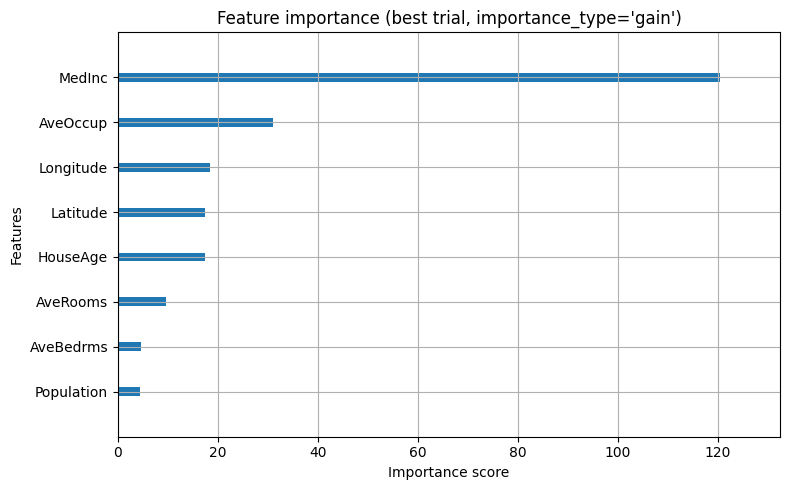

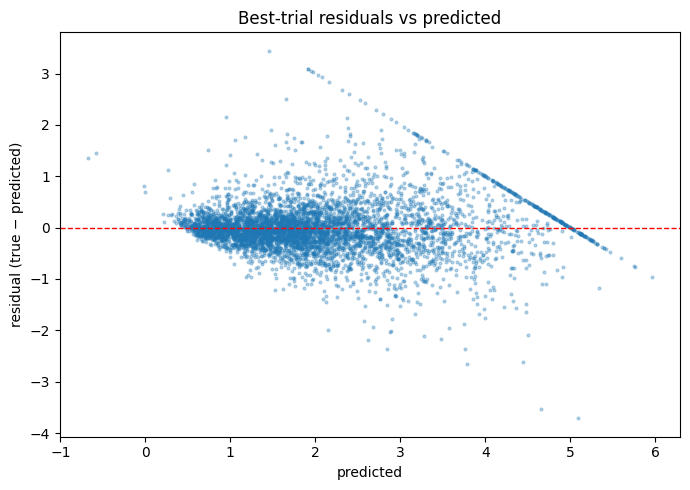

In [7]:
best_params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "verbosity": 0,
    **best_trial.params,
}
best_booster = xgb.train(best_params, dtrain, num_boost_round=50)
best_preds = best_booster.predict(dvalid)
best_residuals = y_valid.values - best_preds

# Feature importance plot \u2014 the metric depends on the booster type.
importance_type = "weight" if best_params["booster"] == "gblinear" else "gain"
fig_imp, ax_imp = plt.subplots(figsize=(8, 5))
xgb.plot_importance(
    best_booster, importance_type=importance_type, ax=ax_imp, show_values=False
)
ax_imp.set_title(
    f"Feature importance (best trial, importance_type={importance_type!r})"
)
fig_imp.tight_layout()

# Residuals plot \u2014 same shape as c_logging_plots.ipynb, logged once on the parent.
fig_res, ax_res = plt.subplots(figsize=(7, 5))
ax_res.scatter(best_preds, best_residuals, s=4, alpha=0.3)
ax_res.axhline(0, color="red", linestyle="--", linewidth=1)
ax_res.set_xlabel("predicted")
ax_res.set_ylabel("residual (true \u2212 predicted)")
ax_res.set_title("Best-trial residuals vs predicted")
fig_res.tight_layout()

# Resume the parent run so the figures attach to *it*, not to a new run.
with mlflow.start_run(run_id=parent_run.info.run_id):
    mlflow.log_figure(fig_imp, "diagnostics/feature_importance.png")
    mlflow.log_figure(fig_res, "diagnostics/residuals.png")
    final_model_info = mlflow.xgboost.log_model(
        xgb_model=best_booster,
        name="final_model",
        input_example=X_train.head(),
        model_format="ubj",
    )

print("Parent model URI:", final_model_info.model_uri)

<div style="text-align: justify; max-width: 90ch">

**Resuming an existing run with `mlflow.start_run(run_id=...)`.** The parent's outer `with`-block from Step 6 already exited,
so the parent is closed. Reopening it by `run_id` is the canonical pattern for "come back later and add to a run". The run goes from `FINISHED` to `RUNNING` while the block is open and back to `FINISHED` when it exits —
entirely safe; the run's start time stays put, and any new log\_\* calls append to the existing run's metadata.

</div>

<div style="text-align: justify; max-width: 90ch">

## Step 8: Inference using the logged final model

Load the final model back via its `model_uri`. In MLflow 3, `log_model` returns a logged-model URI, `models:/m-<id>` (printed above):
it names this model directly, registered or not. A registered version would be `models:/<name>/<version>`, and `runs:/<run_id>/<path>` is the older, run-relative form.
Predict on the full feature frame, attach predictions next to the actuals, sanity-check the head.

</div>

In [8]:
loaded = mlflow.xgboost.load_model(final_model_info.model_uri)
inference = loaded.predict(xgb.DMatrix(X))

infer_df = X.copy()
infer_df["actual_med_house_val"] = y.values
infer_df["predicted_med_house_val"] = inference
infer_df.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,actual_med_house_val,predicted_med_house_val
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,4.114625
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,3.648024
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,4.161043


<div style="text-align: justify; max-width: 90ch">

## Viewing the run in the UI — what the callbacks bought you

Open <http://127.0.0.1:5001/> and click into **Logging Callbacks** → the `study_xbg_mlflow` parent run.

### The Charts tab is the new view

Switch to the **Charts** tab on the parent. You should see three small-multiples charts:

- **`best_so_far_mse`** — a monotonically non-increasing step curve from trial 0 to trial 19. The steepest drops are the trials `champion_callback` printed about.
- **`current_trial_mse`** — a noisy line of all 20 trials. Where it touches `best_so_far_mse`, you have a new champion.
- **`best_so_far_rmse`** — same shape as `best_so_far_mse` but in the target's units ($100k), for human-readable convergence reporting.

Set the **x-axis** to *Step* (not the default *Wall time*) to read the chart in trial-number space. The Step axis is what we logged with `step=frozen_trial.number`;
Wall time would just show training-duration variance.

### Stdout vs MLflow side-by-side

Compare what `champion_callback` printed in this notebook with what's on the parent's Charts tab:

- The printed lines vanish when you close the notebook. The MLflow chart persists in `mlflow.db` and is queryable months later.
- The printed lines name the trial number and improvement %. The chart shows the *full convergence shape* — which prints can't easily convey.
- Together they cover two different audiences: stdout for the person watching the cell run, MLflow for everyone else (future you,
  your collaborator, the on-call data scientist next quarter).

### The other tabs

- **Overview** — the four tags (`project`, `optimizer_engine`, `model_family`, `feature_set_version`) appear here and in the experiment's filter bar.
- **Artifacts** — `diagnostics/feature_importance.png` and `diagnostics/residuals.png`. The refit XGBoost (saved in UBJ format) is not here:
  in MLflow 3 it is a **logged model**, listed under **Logged models** on the run's Overview, with its own page and files.
- **Child runs** (expand-arrow in the runs table) — 20 trials, each with its own model. Click any child to drill down — that trial's own MSE/RMSE are on its page, and its model is under **Logged models**.

</div>

<div style="text-align: justify; max-width: 90ch">

## Aside: `mlflow.xgboost.autolog()` gives the *within-training* curve for free

`a_` and `b_` introduced `mlflow.autolog()` / `mlflow.sklearn.autolog()` as the one-line alternative to manual logging. There's an XGBoost flavor too —
`mlflow.xgboost.autolog()` — and it's worth knowing exactly which slice of this notebook it would have written for you, and which slice it **can't**.

Call it once before training and every `xgb.train(...)` / `XGBRegressor().fit(...)` in the process is patched. For each fit it logs, with no extra code:

- the booster **params** and the **model** (XGBoost flavor, same as our manual `log_model`);
- a **per-boosting-round metric series** for every entry you pass in `evals=[(dvalid, "validation")]` — e.g. `validation-rmse` stepped by **iteration** (boosting round).
  This is the model's *internal learning curve*;
- a **feature-importance plot** artifact — essentially the `xgb.plot_importance(...)` figure we built by hand in Step 7.

So autolog would have handed us the Step-7 importance plot and a within-training convergence curve essentially for free.

**What autolog cannot do here — and why the callbacks still earn their place.** Autolog operates on *one fit at a time*.
It knows nothing about the **Optuna study** wrapped around those fits, so it cannot produce the parent-run `best_so_far_mse` / `best_so_far_rmse` series this notebook builds with `mlflow_progress_callback` —
that curve lives on a *different axis* (**Optuna trial number**, not boosting round) and aggregates *across* trials. Nor would it quieten stdout the way `champion_callback` does.
The two layers are **complementary**, not redundant:

| Axis                                  | What it charts                                      | Produced by                                           |
| ------------------------------------- | --------------------------------------------------- | ----------------------------------------------------- |
| **Boosting round** (inside one model) | `validation-rmse` per iteration, feature importance | `mlflow.xgboost.autolog()` — free                     |
| **Optuna trial** (across the sweep)   | `best_so_far_mse`, `current_trial_mse` convergence  | the manual `mlflow_progress_callback` — this notebook |

**Practical recipe.** Turn on `mlflow.xgboost.autolog()` so each trial's *child* run gets its internal learning curve + importance plot automatically,
and *keep* `mlflow_progress_callback` for the study-level convergence on the *parent*. One caveat carried over from `a_`/`b_`:
autolog uses the flavor's default on-disk format, which for XGBoost in MLflow 3.12 is already `ubj`, so nothing extra is needed for the secure format (Step 7 logs the final model manually anyway,
with `model_format="ubj"` spelled out). Full API: `mlflow.xgboost.autolog` in the [XGBoost flavor docs](https://mlflow.org/docs/latest/python_api/mlflow.xgboost.html).

</div>

<div style="text-align: justify; max-width: 90ch">

## Exercise (optional): rebuild the champion printout from MLflow

`champion_callback`'s printout lives only in this notebook's output; the `best_so_far_mse` history that `mlflow_progress_callback` logged lives on the parent run.
Rebuild the printout from MLflow alone:

1. Fetch the parent run's `best_so_far_mse` history with `MlflowClient().get_metric_history(run_id, key)`. Each entry has a `step` (the trial number) and a `value`.
2. Check that the curve never goes up.
3. Print the trials where it dropped. They should be the trials `champion_callback` printed in Step 6.

Try it in a new cell, then compare with the solution below. The solution only reads from the server, so running or skipping it leaves the rest of the notebook unchanged.

</div>

<div style="text-align: justify; max-width: 90ch">

### Solution

`get_metric_history` returns every value logged under one metric key, not only the latest one that the runs table shows.

</div>

In [9]:
from mlflow import MlflowClient

history = sorted(
    MlflowClient().get_metric_history(parent_run.info.run_id, "best_so_far_mse"),
    key=lambda m: m.step,
)
values = [m.value for m in history]
never_increases = all(later <= earlier for earlier, later in zip(values, values[1:]))
print(f"{len(history)} points, one per trial; never increases: {never_increases}")

print("\nnew champions, read back from MLflow:")
previous = None
for m in history:
    if previous is None or m.value < previous:
        print(f"  trial {m.step:>2}: best_so_far_mse = {m.value:.4f}")
    previous = m.value

20 points, one per trial; never increases: True

new champions, read back from MLflow:
  trial  0: best_so_far_mse = 1.3083
  trial  6: best_so_far_mse = 0.4565
  trial 10: best_so_far_mse = 0.2663
  trial 11: best_so_far_mse = 0.2472


<div style="text-align: justify; max-width: 90ch">

## Next steps

- [Optuna callbacks documentation](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html#optuna.study.Study.optimize) —
  the full `callbacks=[...]` contract, including the pruning callback (`optuna.integration.MLflowCallback` is also worth knowing about —
  it's a built-in MLflow integration that does some of this automatically, with less customization).
- [`mlflow.xgboost`](https://mlflow.org/docs/latest/python_api/mlflow.xgboost.html) — the full XGBoost flavor (`save_model`, `load_model`, `autolog`).
- **Generalizing the metric-history pattern.** Anything you log inside `mlflow_progress_callback` becomes a parent-run time series.
  Useful variants: log the count of trials with each booster type (one metric per booster, all stepped by trial number) → you get a Charts-tab view of which boosters Optuna is spending its budget on.
  Same pattern, different metric names.
- **Pruning unpromising trials.** With XGBoost + Optuna you can implement intermediate-value reporting via `xgb.callback.TrainingCallback` + Optuna's `report` API,
  then prune trials early with `MedianPruner` or `HyperbandPruner`. That's a follow-on tutorial.

</div>